# Fair comparison: where does the advantage come from?

Two questions:

1. Is our advantage only the greedy validation-driven search, or does it come
   from the moves themselves?
2. Does it come from **composite / structural moves** rather than working at
   the level of single parameters?

**Design.** Two factors are crossed. Berman et al.'s iterative Fisher-distance
score $\sqrt{F_{kk}(\theta)}\,|\theta_k|$, computed with their own code,
proposes every single-parameter move.

| factor | levels |
|---|---|
| granularity | **W**: single parameters only · **S**: structural moves only (merge, mean, saturation, step, head / attention / rank moves) · **W+S**: both |
| selection data | **static**: one-shot ranking, no data in the loop · **train**: each move chosen on training data · **valA**: each move chosen on held-out data (our rule) |

**One stopping rule for everybody.** The validation split is halved once, at
random. **valA** may be used to choose moves. **valB** is used by every method,
greedy or one-shot, only for the same anchored paired 2σ stop test against the
original model. The test split is reported only.

**Tie-break:** fewest remaining parameters, then lowest loss. **Criterion:**
per-sample log loss. No retraining anywhere.

The *static* row covers:
- W: Berman et al.'s four schemes, plus magnitude, OBD, Wanda and random;
- S: classical mean-ablation.

`W | valA | magnitude` and `W+S | valA | obd` are the same design with a
different single-parameter proposer.

In [1]:
import os, sys
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
sys.path.insert(0, os.path.abspath("."))
from nnprune import experiments as E
RECOMPUTE = False      # True: rerun (MLP ~30 min for 3 seeds, transformer ~1.5 h on a laptop CPU)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda x: f"{x:.4g}")

PAL  = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
INK2, GRID = "#52514e", "#e4e3de"
plt.rcParams.update({"figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.6, "xtick.color": INK2, "ytick.color": INK2, "axes.spines.top": False,
    "axes.spines.right": False, "legend.frameon": False, "legend.fontsize": 8.5, "font.size": 9.5})

def stop_table(fair, rel_tol=0.0):
    S = E.stop_points(fair, rel_tols=(rel_tol,)); g = S.groupby("method")
    T = pd.DataFrame({"% removed": 100 * g["frac_removed"].mean(), "sd": 100 * g["frac_removed"].std(),
                      "params left": g["k_eff"].mean(), "test loss": g["test_loss"].mean(),
                      "test acc": g["test_acc"].mean()})
    return T.sort_values("% removed", ascending=False)

def grid_table(fair, rel_tol=0.0, static_W="fdist_iterative", static_S="mean_ablation"):
    T = stop_table(fair, rel_tol)["% removed"]
    get = lambda m: T.get(m, np.nan)
    return pd.DataFrame({
        "static (one-shot)": [get(static_W), get(static_S), np.nan],
        "train-selected":    [get("W | train | fdist"), get("S | train"), get("W+S | train | fdist")],
        "valA-selected":     [get("W | valA | fdist"), get("S | valA"), get("W+S | valA | fdist")],
    }, index=["W  (single parameters)", "S  (structural)", "W+S"]).rename_axis(
        f"% removed at the valB stop, margin {100 * rel_tol:g}% of base loss")

def margin_table(fair, methods, rel_tols=(0.0, 0.005, 0.01, 0.02)):
    SP = E.stop_points(fair, rel_tols=rel_tols)
    T = SP[SP.method.isin(methods)].groupby(["method", "rel_tol"])["frac_removed"].mean().unstack() * 100
    T.columns = [f"margin {100 * c:g}%" for c in T.columns]
    return T.loc[[m for m in methods if m in T.index]]

def at_sparsity(fair, metric, grid=(0.1, 0.3, 0.5, 0.7, 0.9)):
    # value of `metric` at the last point with <= f removed, mean over seeds
    D = pd.concat([fair["paths"], fair["statics"]])
    rows = {}
    for m, dm in D.groupby("method"):
        vals = []
        for f in grid:
            per_seed = []
            for _, ds in dm.groupby("seed"):
                d = ds[ds.frac_removed <= f + 1e-9].sort_values("frac_removed")
                per_seed.append(d[metric].iloc[-1] if len(d) and d.frac_removed.max() >= f - 0.05 else np.nan)
            vals.append(np.nanmean(per_seed) if np.isfinite(per_seed).any() else np.nan)
        rows[m] = vals
    return pd.DataFrame(rows, index=[f"{int(100 * f)}%" for f in grid]).T

def curves(fair, metric, ylabel, title, seed, logy=False):
    show = ["W+S | valA | fdist", "S | valA", "W | valA | fdist", "W+S | train | fdist", "W | train | fdist",
            "fdist_iterative"]
    D = pd.concat([fair["paths"], fair["statics"]]); D = D[D.seed == seed]
    fig, ax = plt.subplots(figsize=(7.4, 4.1))
    for k, m in enumerate(show):
        d = D[D.method == m].sort_values("frac_removed")
        if d.empty: continue
        ax.plot(100 * d.frac_removed, d[metric], color=PAL[k], lw=2.0 if k == 0 else 1.5, label=m)
        sp = E.stop_points({"paths": fair["paths"][fair["paths"].seed == seed],
                            "statics": fair["statics"][fair["statics"].seed == seed]}, rel_tols=(0.01,))
        r = sp[sp.method == m].iloc[0]
        ax.plot(100 * r.frac_removed, r[metric], "o", ms=8, mfc="#fcfcfb", mec=PAL[k], mew=2)
    if logy: ax.set_yscale("log")
    ax.set_xlabel("% of parameters removed (k_eff)   ·   ring = valB stop, margin 1%"); ax.set_ylabel(ylabel); ax.set_title(title, loc="left")
    ax.legend(loc="best"); plt.tight_layout(); plt.show()

## Moons MLP (3 seeds)

In [2]:
fm = E.run_fair("mlp", recompute=RECOMPUTE)
display(grid_table(fm, 0.0))
grid_table(fm, 0.01)

,static (one-shot),train-selected,valA-selected
"% removed at the valB stop, margin 0% of base loss",,,
W (single parameters),5.1,15.66,10.16
S (structural),11.81,63.64,65.69
W+S,NaN,63.91,62.62


,static (one-shot),train-selected,valA-selected
"% removed at the valB stop, margin 1% of base loss",,,
W (single parameters),5.766,18.01,10.16
S (structural),14.42,93.81,94.99
W+S,NaN,94.25,96.6


**How the stop depends on the margin.** The margin is $\delta$ in
$\overline{\Delta\ell}\le 2\,\widehat{SE}+\delta$, with $\delta$ a fraction of
the base validation loss. With $\delta=0$ the test also rejects tiny but
systematic changes: their paired SE is tiny too.

In [3]:
KEY = ["W+S | valA | fdist", "S | valA", "W | valA | fdist", "W+S | train | fdist", "S | train",
       "W | train | fdist", "W | valA | magnitude", "W+S | valA | obd",
       "fdist_iterative", "fdist_exact", "fdist_global", "fdist_one_shot", "magnitude", "mean_ablation"]
margin_table(fm, KEY)

,margin 0%,margin 0.5%,margin 1%,margin 2%
method,,,,
W+S | valA | fdist,62.62,91.47,96.6,96.91
S | valA,65.69,94.94,94.99,94.99
W | valA | fdist,10.16,10.16,10.16,18.8
W+S | train | fdist,63.91,93.66,94.25,96.28
S | train,63.64,93.22,93.81,96.08
W | train | fdist,15.66,16.97,18.01,21.82
W | valA | magnitude,18.88,20.36,21.03,21.37
W+S | valA | obd,66.04,94.89,94.93,94.93
fdist_iterative,5.1,5.766,5.766,5.766


In [4]:
stop_table(fm, 0.01)

,% removed,sd,params left,test loss,test acc
method,,,,,
W+S | valA | fdist,96.6,0.9149,180,0.1429,0.9413
S | valA,94.99,2.934,265.7,0.1508,0.938
W+S | valA | obd,94.93,2.902,269,0.1398,0.942
W+S | train | fdist,94.25,4.819,305,0.1341,0.94
S | train,93.81,4.441,328.3,0.1448,0.9387
W | valA | magnitude,21.03,7.345,4186,0.16,0.9413
W | train | fdist,18.01,9.785,4346,0.1468,0.944
mean_ablation,14.42,6.292,4536,0.1429,0.9427
W | valA | fdist,10.16,9.828,4763,0.1448,0.9427


**Test loss at matched sparsity** (mean over seeds; blank where a method's
curve does not reach that sparsity before it stops or ends).

In [5]:
at_sparsity(fm, "test_loss").sort_values("50%")

,10%,30%,50%,70%,90%
S | train,0.1322,0.1321,0.1321,0.1326,0.133
W+S | train | fdist,0.1322,0.1321,0.1321,0.1326,0.1331
S | valA,0.1321,0.1321,0.1322,0.132,0.1344
W+S | valA | fdist,0.1321,0.1328,0.133,0.1329,0.1348
W+S | valA | obd,0.1321,0.1328,0.133,0.1325,0.1334
random,0.1821,0.2691,0.3132,0.5587,0.6666
W | train | fdist,0.1365,0.167,0.3133,0.5621,0.6706
W | valA | magnitude,0.1419,0.1846,0.3159,0.5953,0.6836
W | valA | fdist,0.1367,0.1881,0.3268,0.608,0.683
mean_ablation,0.1352,0.1733,0.3776,0.6432,0.683


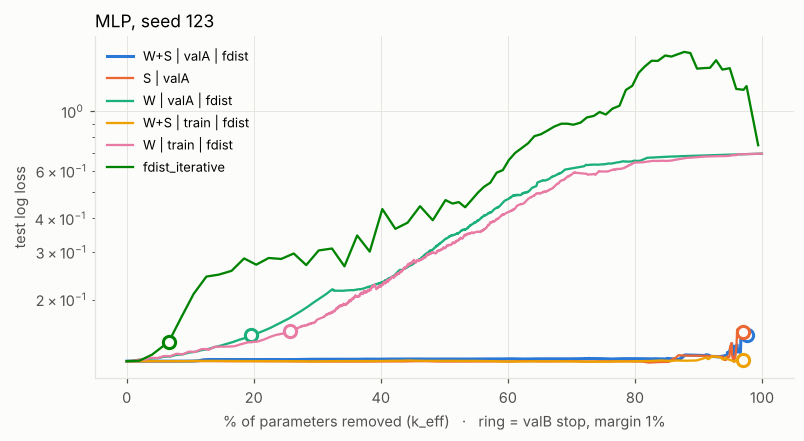

In [6]:
curves(fm, "test_loss", "test log loss", "MLP, seed 123", 123, logy=True)

## One-layer transformer, $a+b \bmod 59$ (seed 0)

The base loss is $8\cdot10^{-4}$ on a deterministic task, so margins of 0
and 1% coincide. Larger margins are shown too: 100% means the loss may double,
to about $1.6\cdot10^{-3}$.

In [7]:
ft = E.run_fair("transformer", recompute=RECOMPUTE)
display(grid_table(ft, 0.0))
grid_table(ft, 1.0)

,static (one-shot),train-selected,valA-selected
"% removed at the valB stop, margin 0% of base loss",,,
W (single parameters),8,8.036,7.925
S (structural),0,43.25,44.15
W+S,NaN,47.87,43.68


,static (one-shot),train-selected,valA-selected
"% removed at the valB stop, margin 100% of base loss",,,
W (single parameters),14,26.68,26.99
S (structural),12.82,52.48,52.7
W+S,NaN,65.19,66.33


In [8]:
margin_table(ft, KEY, rel_tols=(0.0, 0.01, 0.1, 1.0, 10.0))

,margin 0%,margin 1%,margin 10%,margin 100%,margin 1000%
method,,,,,
W+S | valA | fdist,43.68,44.33,48.5,66.33,77.15
S | valA,44.15,44.38,47.53,52.7,53.15
W | valA | fdist,7.925,8.706,16.74,26.99,40.46
W+S | train | fdist,47.87,48.15,51.55,65.19,78.1
S | train,43.25,43.93,47.75,52.48,52.7
W | train | fdist,8.036,9.041,14.18,26.68,40.28
W | valA | magnitude,8.594,9.153,14.96,26.12,37.73
W+S | valA | obd,32.76,33.21,50,62.1,70.08
fdist_iterative,8,8,10,14,28.01


In [9]:
stop_table(ft, 1.0)

,% removed,sd,params left,test loss,test acc
method,,,,,
W+S | valA | fdist,66.33,NaN,1.931e+04,0.001995,1
W+S | train | fdist,65.19,NaN,1.996e+04,0.001808,1
W+S | valA | obd,62.1,NaN,2.173e+04,0.001806,1
S | valA,52.7,NaN,2.712e+04,0.001233,1
S | train,52.48,NaN,2.725e+04,0.001227,1
W | valA | fdist,26.99,NaN,4.186e+04,0.00189,1
W | train | fdist,26.68,NaN,4.204e+04,0.001838,1
W | valA | magnitude,26.12,NaN,4.236e+04,0.001846,1
magnitude,17.88,NaN,4.709e+04,0.00176,1


In [10]:
display(at_sparsity(ft, "test_acc").sort_values("50%", ascending=False))
at_sparsity(ft, "test_loss").sort_values("50%")

,10%,30%,50%,70%,90%
S | train,1,1,1,0.837,0.01378
S | valA,1,1,1,0.9633,0.01378
W | train | fdist,1,1,1,0.5017,0.03215
W+S | train | fdist,1,1,1,1,0.1803
W+S | valA | obd,1,1,1,1,0.01952
W+S | valA | fdist,1,1,1,1,0.2652
W | valA | fdist,1,1,0.9989,0.4696,0.031
W | valA | magnitude,1,1,0.9816,0.2273,0.02181
fdist_iterative,1,1,0.6808,0.101,0.01837
magnitude,1,0.9966,0.597,0.05511,0.02641


,10%,30%,50%,70%,90%
W+S | train | fdist,0.0008352,0.0008293,0.0009725,0.002577,2.905
W+S | valA | fdist,0.0008432,0.0008556,0.001055,0.002656,2.568
W+S | valA | obd,0.0008456,0.0009105,0.001081,0.007039,5.042
S | train,0.0008353,0.0008437,0.001088,0.5611,5.356
S | valA,0.0008424,0.0008551,0.001116,0.1877,6.805
W | train | fdist,0.0008753,0.002424,0.04991,1.751,3.998
W | valA | fdist,0.0008803,0.002435,0.05412,1.869,4.036
W | valA | magnitude,0.0008695,0.002995,0.1556,2.517,4.076
fdist_iterative,0.0009248,0.01079,0.9324,4.201,5.053
magnitude,0.0009639,0.0319,1.313,4.291,4.228


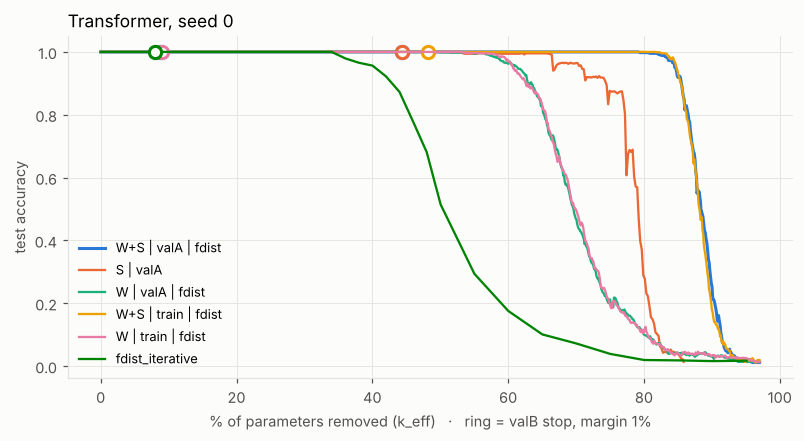

In [11]:
curves(ft, "test_acc", "test accuracy", "Transformer, seed 0", 0)

## Findings

These findings are for the cached run: MLP seeds 123, 7 and 42, transformer seed 0.

**1. Held-out data in the loop is not where the advantage comes from.** In both
models, choosing each move on training data gives the same result as choosing
it on valA.

| model | arm | train-selected | valA-selected |
|---|---|---|---|
| MLP | W+S | 94% | 97% |
| MLP | S | 94% | 95% |
| transformer | W+S | 65% | 66% |

(Margin 1% for the MLP, margin = base loss for the transformer.)

**2. Composite / structural moves are where it comes from.** With the same
proposer (Berman et al.'s score), the same tie-break and the same stop rule:

- **MLP, margin 1%:**

  | arm | % removed |
  |---|---|
  | single parameters, greedy | 10–21 |
  | single parameters, one-shot (Berman's family) | 6–9 |
  | structural, greedy | 94–97 |

  At matched sparsity, structural arms keep the base test loss (0.132) up to
  90% removed. The best single-parameter arm is already at 0.31 at 50%.
- **Transformer:**

  | arm | test accuracy at 70% removed |
  |---|---|
  | structural | 1.000 |
  | single parameters, greedy | 0.47–0.50 |
  | Berman iterative, one-shot | 0.10 |
  | magnitude | 0.06 |

  Here the combination W+S beats S alone. S on its own runs out at 86%
  (embeddings and unembedding have no structural moves) and is less accurate
  at 70% (0.84–0.96).

**3. Greedy loss evaluation helps single parameters, but only moderately.** The
gain is MLP 6% → 10–21%, and on the transformer test accuracy at 50% goes from
0.68 to 0.999. One-shot structural pruning (classical mean-ablation) stays
poor: 14% on the MLP, 13% on the transformer. Composite moves pay off only when
each one is evaluated.

**4. The pure 2σ rule needs a practical margin.** With δ = 0 the MLP stop points
are bimodal (sd ≈ 47 points across seeds). A move that changes the loss by
0.0002 with SE 0.0001 is "significant" and ends the path, even though later
steps pass again. Any margin ≥ 0.5% of the base loss removes this. On the
transformer (base loss 8·10⁻⁴), δ = 0 and δ = 1% give the same stops.

**Caveats.**
- One transformer seed.
- Single-parameter moves exclude biases; Berman's protocol prunes them too.
- Structural moves carry their own closed-form compensation (folds, merges),
  which is part of what "composite" means here. Ablating that compensation is
  the next test.
- Counts are parameters (k_eff), not FLOPs.
